# Chapter 4: Dynamics without coordinates

Reproduce the chapter's examples and start its exercises: the conditioning of the
Euler-angle mass matrix, Hamilton's principle on a thrown ball, the spherical pendulum,
the tumbling book, the quadrotor with a cable-suspended load, and integration that stays
on the manifold.

The equations of motion are typed in the chapter's notation and then compared with a
second derivation by the `geomech` library.

In [1]:
import subprocess
import sys

try:
    import geomech
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geomech"])
    import geomech

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

print("geomech", geomech.__version__)
G = 9.81
E3 = np.array([0.0, 0.0, 1.0])


def hat(v):
    return np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    """exp(hat(w)) by Rodrigues' formula."""
    th = np.linalg.norm(w)
    if th < 1e-12:
        return np.eye(3) + hat(w)
    K = hat(w / th)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def unit(v):
    return np.asarray(v, float) / np.linalg.norm(v)


def tangent(q, v):
    """Part of v in the tangent plane of the sphere at q."""
    return v - (v @ q) * q

geomech 1.1.0


## 1. The puzzle: one pendulum, two mass matrices

In yaw-pitch-roll angles the mass matrix of the 3D pendulum is $E^\top J E$. In the body
frame it is $J$.

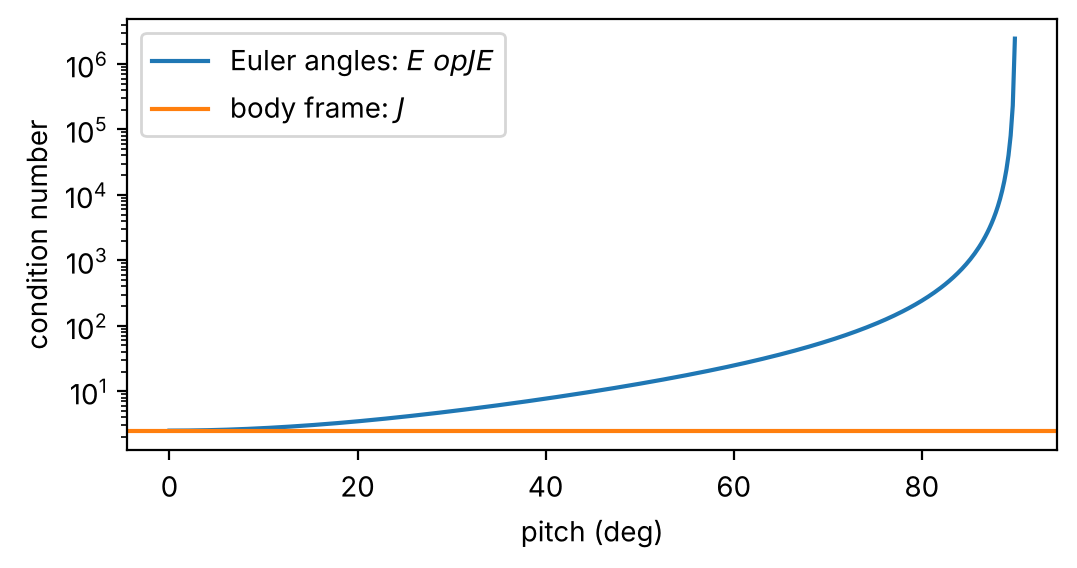

pitch  0 deg: cond(E'JE) =       2.5    cond(J) = 2.5
pitch 60 deg: cond(E'JE) =      24.7    cond(J) = 2.5
pitch 85 deg: cond(E'JE) =     974.2    cond(J) = 2.5
pitch 89 deg: cond(E'JE) =   24416.6    cond(J) = 2.5


In [2]:
J_p = np.diag([0.20, 0.25, 0.10])        # inertia about the pivot, kg·m²
m_p, rho_p = 1.0, np.array([0.0, 0.0, -0.4])


def E_mat(th, phi):
    return np.array([[-np.sin(th), 0, 1],
                     [np.cos(th) * np.sin(phi), np.cos(phi), 0],
                     [np.cos(th) * np.cos(phi), -np.sin(phi), 0]])


pitch = np.radians(np.linspace(0, 89.9, 400))
cond = [np.linalg.cond(E_mat(t, np.radians(20)).T @ J_p @ E_mat(t, np.radians(20))) for t in pitch]
plt.figure(figsize=(6, 2.8))
plt.semilogy(np.degrees(pitch), cond, label="Euler angles: $E^\top J E$")
plt.axhline(np.linalg.cond(J_p), color="C1", label="body frame: $J$")
plt.xlabel("pitch (deg)"); plt.ylabel("condition number"); plt.legend(); plt.show()
for deg in (0, 60, 85, 89):
    Em = E_mat(np.radians(deg), np.radians(20))
    print(f"pitch {deg:2d} deg: cond(E'JE) = {np.linalg.cond(Em.T @ J_p @ Em):9.1f}    cond(J) = {np.linalg.cond(J_p):.1f}")

## 2. Hamilton's principle for a thrown ball

Bump the true path by $\epsilon\sin(\pi t/t_f)\,e_3$. The action changes by
$m\epsilon^2\pi^2/(4 t_f)$: no first-order term.

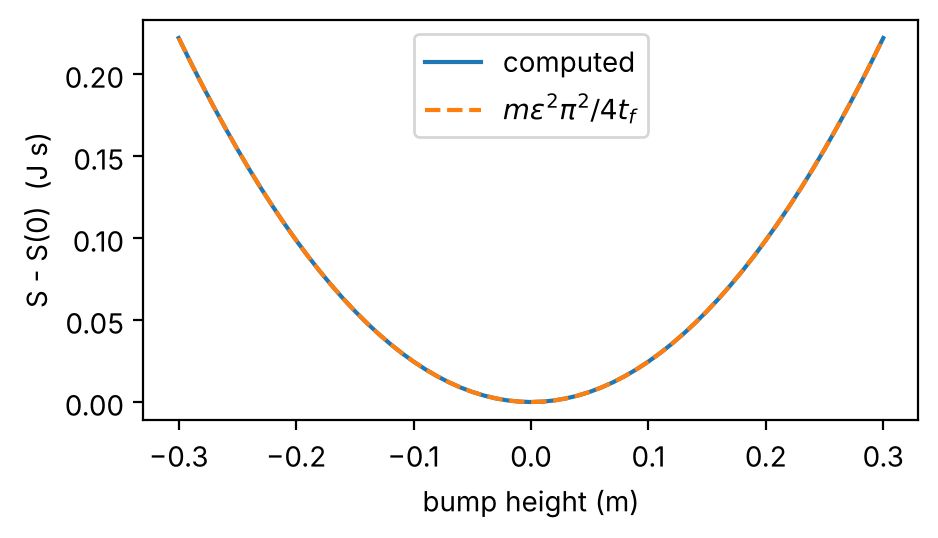

10 cm bump: action rises by 0.0247 J s


In [3]:
m_b, tf = 1.0, 1.0
t = np.linspace(0, tf, 20001)
v0 = np.array([2.0, 0.0, 0.5 * G * tf])


def action(eps):
    z = v0[2] * t - 0.5 * G * t**2 + eps * np.sin(np.pi * t / tf)
    vz = v0[2] - G * t + eps * np.pi / tf * np.cos(np.pi * t / tf)
    return np.trapezoid(0.5 * m_b * (v0[0]**2 + vz**2) - m_b * G * z, t)


eps = np.linspace(-0.3, 0.3, 61)
dS = np.array([action(e) - action(0.0) for e in eps])
plt.figure(figsize=(5, 2.6))
plt.plot(eps, dS, label="computed"); plt.plot(eps, m_b * eps**2 * np.pi**2 / (4 * tf), "--", label=r"$m\epsilon^2\pi^2/4t_f$")
plt.xlabel("bump height (m)"); plt.ylabel("S - S(0)  (J s)"); plt.legend(); plt.show()
print(f"10 cm bump: action rises by {action(0.1) - action(0.0):.4f} J s")

## 3. Variations that stay on the manifold

Finite-difference checks of $\delta q = \xi\times q$ on the sphere and of
$\delta\Omega = \dot\eta + \Omega\times\eta$ on the rotation group.

In [4]:
def curve_R(s):
    return expm_so3(0.8 * np.sin(s) * unit([1, -1, 0.5])) @ expm_so3(1.1 * s * unit([0.2, 0.3, 1.0]))


def eta_of(s):
    return np.array([np.cos(s), 0.5 * s, np.sin(2 * s) - 0.2])


def Omega(s, eps, d=1e-5):
    Rv = lambda u: curve_R(u) @ expm_so3(eps * eta_of(u))
    return vee(Rv(s).T @ (Rv(s + d) - Rv(s - d)) / (2 * d))


s0, e = 0.37, 1e-5
lhs = (Omega(s0, e) - Omega(s0, -e)) / (2 * e)
rhs = (eta_of(s0 + e) - eta_of(s0 - e)) / (2 * e) + np.cross(Omega(s0, 0.0), eta_of(s0))
print("delta Omega, finite difference:", lhs)
print("eta_dot + Omega x eta:         ", rhs)

q = unit([0.6, 0.2, -0.77]); xi = tangent(q, np.array([0.3, -0.4, 0.5]))
print("delta q, finite difference:", (expm_so3(e * xi) @ q - expm_so3(-e * xi) @ q) / (2 * e))
print("xi x q:                    ", np.cross(xi, q))

delta Omega, finite difference: [-0.76140622  1.56225419  1.84848109]
eta_dot + Omega x eta:          [-0.76140622  1.56225413  1.8484812 ]
delta q, finite difference: [0.20874236 0.53289515 0.3010707 ]
xi x q:                     [0.20874236 0.53289515 0.3010707 ]


## 4. The spherical pendulum

$m l^2\dot\omega = -m g l\, q\times e_3$, $\dot q = \omega\times q$, and the tension
$T = m l\|\dot q\|^2 - m g\, e_3\cdot q$. Released from the horizontal, the tension at the
bottom is $3mg$.

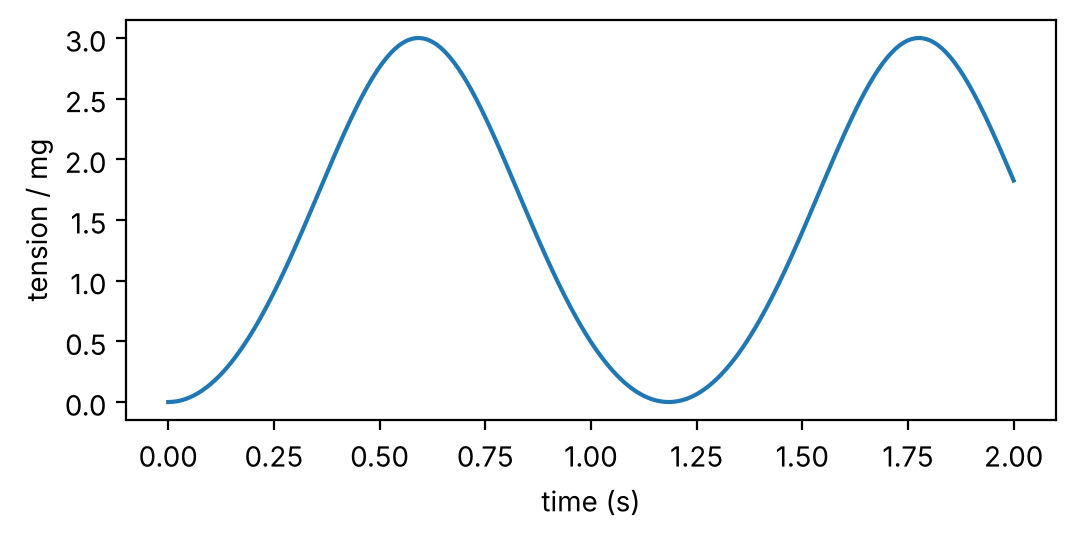

max tension = 29.430 N = 3.0000 mg,  energy spread 5.5e-10 J


In [5]:
m, l = 1.0, 1.0


def sph_rhs(_, s):
    q, om = s[:3], s[3:]
    return np.concatenate([np.cross(om, q), -(G / l) * np.cross(q, E3)])


sol = solve_ivp(sph_rhs, [0, 2.0], np.r_[1.0, 0, 0, 0, 0, 0], rtol=1e-11, atol=1e-12, dense_output=True)
ts = np.linspace(0, 2.0, 400)
Q, W = sol.sol(ts)[:3].T, sol.sol(ts)[3:].T
T = m * l * np.sum(W * W, axis=1) - m * G * Q[:, 2]
energy = 0.5 * m * l**2 * np.sum(W * W, axis=1) + m * G * l * Q[:, 2]
plt.figure(figsize=(6, 2.6))
plt.plot(ts, T / (m * G)); plt.xlabel("time (s)"); plt.ylabel("tension / mg"); plt.show()
print(f"max tension = {T.max():.3f} N = {T.max() / (m * G):.4f} mg,  energy spread {np.ptp(energy):.1e} J")

The same model from `geomech`. Its convention is `E = -(Euler-Lagrange) + forcing`, and an
equation on $S^2$ holds on the tangent plane only. `accelerations` does the projection.

In [6]:
from geomech import check_eom, compute_eom, systems, to_standard_form
from geomech.codegen import load_module, module_source
from geomech.simulation import accelerations


def derive(name, **kw):
    sysm = systems.get(name, **kw)
    eom = compute_eom(sysm.L, sysm.dW, sysm.variables)
    err = check_eom(sysm.L, sysm.dW, sysm.variables, eom, inputs=sysm.inputs)
    sf = to_standard_form(eom, sysm.variables, sysm.inputs)
    layout = sysm.layout()
    return load_module(module_source(sf, layout, lagrangian=sysm.L), name), layout, dict(sysm.params), eom, err


sp_mod, sp_layout, sp_p, sp_eom, err = derive("spherical_pendulum")
for key, (_, eq) in sp_eom.items():
    print(key, ":", eq)
print(f"check_eom error {err:.1e}")
rng = np.random.default_rng(0)
q = unit(rng.normal(size=3)); om = tangent(q, rng.normal(size=3))
mine = -(sp_p["g"] / sp_p["l"]) * np.cross(q, E3)
theirs = accelerations(sp_mod, sp_layout.pack(q=q, omega_q=om), None, sp_p)
print("chapter:", mine, "\ngeomech:", theirs)

\xi_{q} : (\frac{d}{dt}(\omega_{q})*m*l*l*(-1)+Cross(q,e3)*m*g*l*(-1)+M)
check_eom error 1.9e-08
chapter: [ 1.94620911  1.85229594 -0.        ] 
geomech: [1.94620911e+00 1.85229594e+00 5.84006625e-17]


## 5. Toss a book: Euler's equation and the intermediate axis

$J\dot\Omega + \Omega\times J\Omega = 0$ for a 0.3 kg, 20 x 13 x 3 cm block.

e1: energy spread 6.4e-14, spatial momentum drift 2.7e-12


e2: energy spread 1.1e-11, spatial momentum drift 2.8e-11


e3: energy spread 1.1e-13, spatial momentum drift 3.3e-12


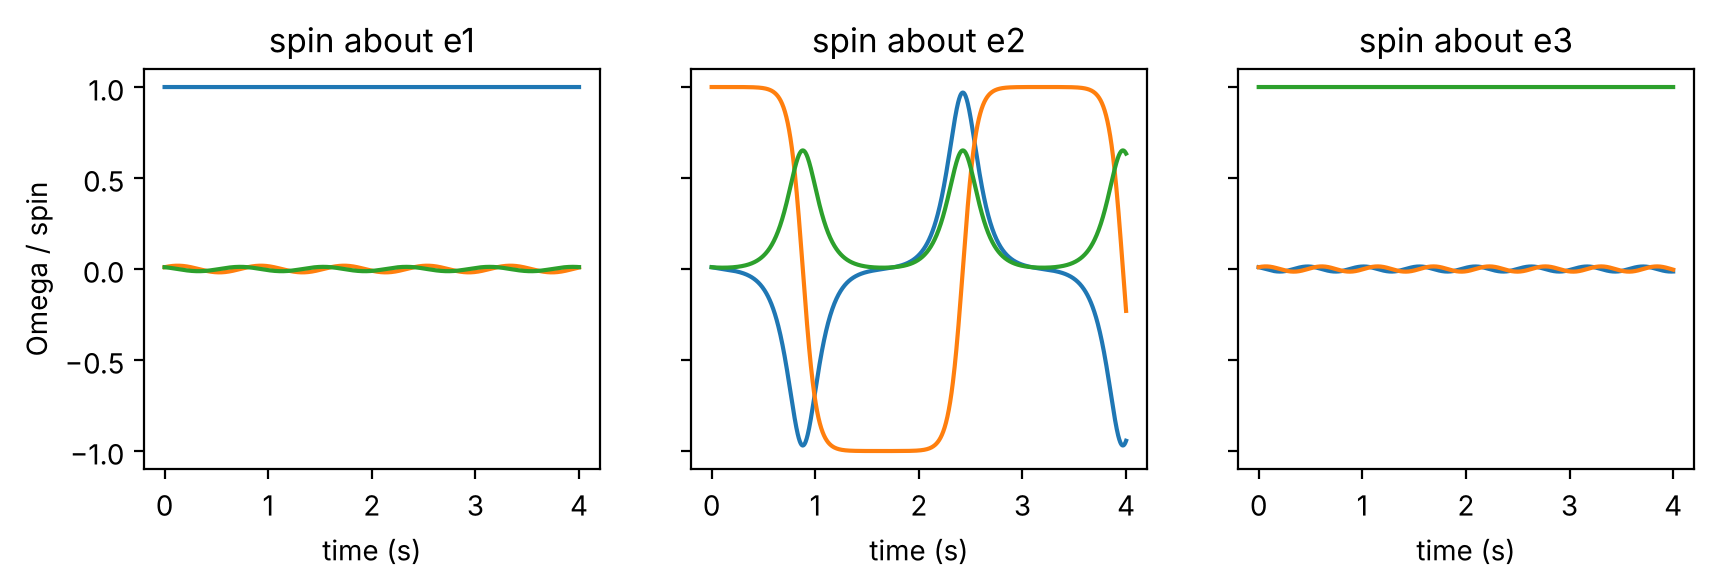

inertias (1e-3 kg·m²): [0.445 1.022 1.422],  growth rate about e2: 7.59 /s


In [7]:
dims, mb = np.array([0.20, 0.13, 0.03]), 0.3
Jb = mb / 12 * np.array([dims[1]**2 + dims[2]**2, dims[0]**2 + dims[2]**2, dims[0]**2 + dims[1]**2])
spin = 2 * np.pi * 2.0


def body_rhs(_, s):
    R, Om = s[:9].reshape(3, 3), s[9:]
    return np.concatenate([(R @ hat(Om)).ravel(), np.cross(Jb * Om, Om) / Jb])


fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, axis in zip(axes, range(3)):
    Om0 = 0.01 * spin * np.ones(3); Om0[axis] = spin
    sol = solve_ivp(body_rhs, [0, 4], np.r_[np.eye(3).ravel(), Om0], rtol=1e-10, atol=1e-12, t_eval=np.linspace(0, 4, 1200))
    ax.plot(sol.t, sol.y[9:].T / spin); ax.set_title(f"spin about e{axis + 1}"); ax.set_xlabel("time (s)")
    R = sol.y[:9].T.reshape(-1, 3, 3)
    H = np.einsum("tij,j,tj->ti", R, Jb, sol.y[9:].T)
    Ek = 0.5 * np.sum(Jb * sol.y[9:].T**2, axis=1)
    print(f"e{axis + 1}: energy spread {np.ptp(Ek) / Ek[0]:.1e}, spatial momentum drift {np.abs(H - H[0]).max() / np.linalg.norm(H[0]):.1e}")
axes[0].set_ylabel("Omega / spin"); plt.show()
lam = spin * np.sqrt((Jb[1] - Jb[0]) * (Jb[2] - Jb[1]) / (Jb[0] * Jb[2]))
print(f"inertias (1e-3 kg·m²): {np.round(Jb * 1e3, 3)},  growth rate about e2: {lam:.2f} /s")

## 6. Quadrotor with a cable-suspended load

The chapter's equations on $\mathbb{R}^3\times S^2\times\mathrm{SO}(3)$, compared with `geomech` at a random
state, then the thought experiment: cut the thrust and watch the cable rate.

In [8]:
ql_mod, ql_layout, ql_p, _, err = derive("quadrotor_suspended_load")
mQ, mL, lc, JQ = ql_p["m_Q"], ql_p["m_L"], ql_p["l"], ql_p["J"]
print(f"check_eom error {err:.1e}")


def load_accels(q, om, R, Om, f, tau):
    u = f * R @ E3
    vL_dot = ((q @ u) - mQ * lc * (om @ om)) * q / (mQ + mL) - G * E3
    om_dot = -np.cross(q, u) / (mQ * lc)
    Om_dot = np.linalg.solve(JQ, tau - np.cross(Om, JQ @ Om))
    return vL_dot, om_dot, Om_dot


q = unit(rng.normal(size=3)); om = tangent(q, rng.normal(size=3))
R, Om, f, tau = expm_so3(rng.normal(size=3)), rng.normal(size=3), 12.0, rng.normal(size=3)
state = ql_layout.pack(x_L=np.zeros(3), q=q, R=R, x_L_dot=np.zeros(3), omega_q=om, Omega_R=Om)
print("chapter:", np.round(np.concatenate(load_accels(q, om, R, Om, f, tau)), 6))
print("geomech:", np.round(accelerations(ql_mod, state, np.r_[f, tau], ql_p), 6))

check_eom error 4.1e-08
chapter: [  4.726177   3.432571 -12.360596   0.427724  -0.386653   0.272206
  19.406328  41.682762  -4.314044]
geomech: [  4.726177   3.432571 -12.360596   0.427724  -0.386653   0.272206
  19.406328  41.682762  -4.314044]


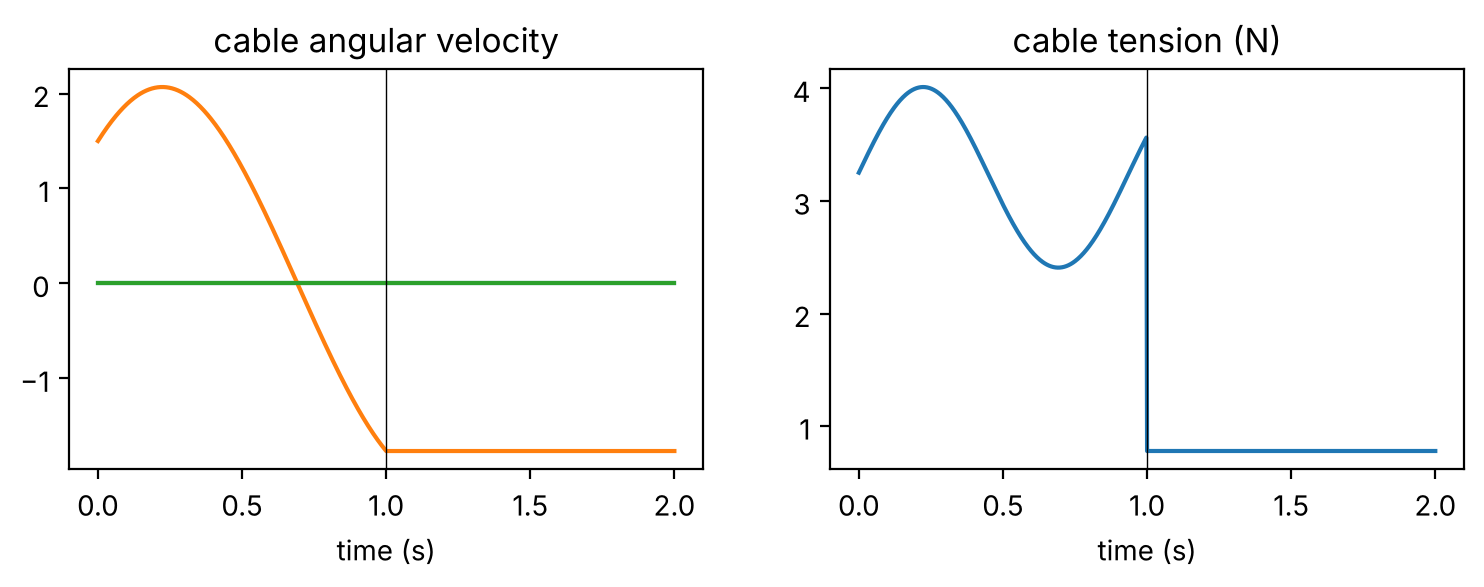

after the cut the cable rate is constant: [0. 0. 0.]


In [9]:
def load_rhs(t, s, thrust):
    vL, q, om, R, Om = s[3:6], s[6:9], s[9:12], s[12:21].reshape(3, 3), s[21:]
    vLd, omd, Omd = load_accels(q, om, R, Om, thrust(t), np.zeros(3))
    return np.concatenate([vL, vLd, np.cross(om, q), omd, (R @ hat(Om)).ravel(), Omd])


q0 = unit([0.4, 0.0, -0.9])
s0 = np.r_[np.zeros(3), np.zeros(3), q0, tangent(q0, [0.0, 1.5, 0.0]), np.eye(3).ravel(), np.zeros(3)]
thrust = lambda t: (mQ + mL) * G if t < 1.0 else 0.0          # motors cut at t = 1 s
sol = solve_ivp(load_rhs, [0, 2], s0, args=(thrust,), max_step=1e-3, t_eval=np.linspace(0, 2, 801))
om_t = sol.y[9:12].T
tension = mL / (mQ + mL) * (mQ * lc * np.sum(om_t**2, axis=1)
                            - np.array([sol.y[6:9, k] @ (thrust(tk) * sol.y[12:21, k].reshape(3, 3) @ E3) for k, tk in enumerate(sol.t)]))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9, 2.6))
a0.plot(sol.t, om_t); a0.axvline(1.0, color="k", lw=0.5); a0.set_title("cable angular velocity"); a0.set_xlabel("time (s)")
a1.plot(sol.t, tension); a1.axvline(1.0, color="k", lw=0.5); a1.set_title("cable tension (N)"); a1.set_xlabel("time (s)")
plt.show()
print("after the cut the cable rate is constant:", np.ptp(om_t[sol.t > 1.01], axis=0))

## 7. Integrating on the manifold

The 3D pendulum $J\dot\Omega + \Omega\times J\Omega = m g (R^\top e_3)\times\rho$, integrated
by classical RK4 on the entries of $R$ and by RK4 on a rotation vector with an exponential
update.

RK4 on entries of R       : |R'R - I| = 4.6e-04,  energy error = 2.9e-04 J


RK4 + exponential update  : |R'R - I| = 9.4e-15,  energy error = 2.2e-04 J


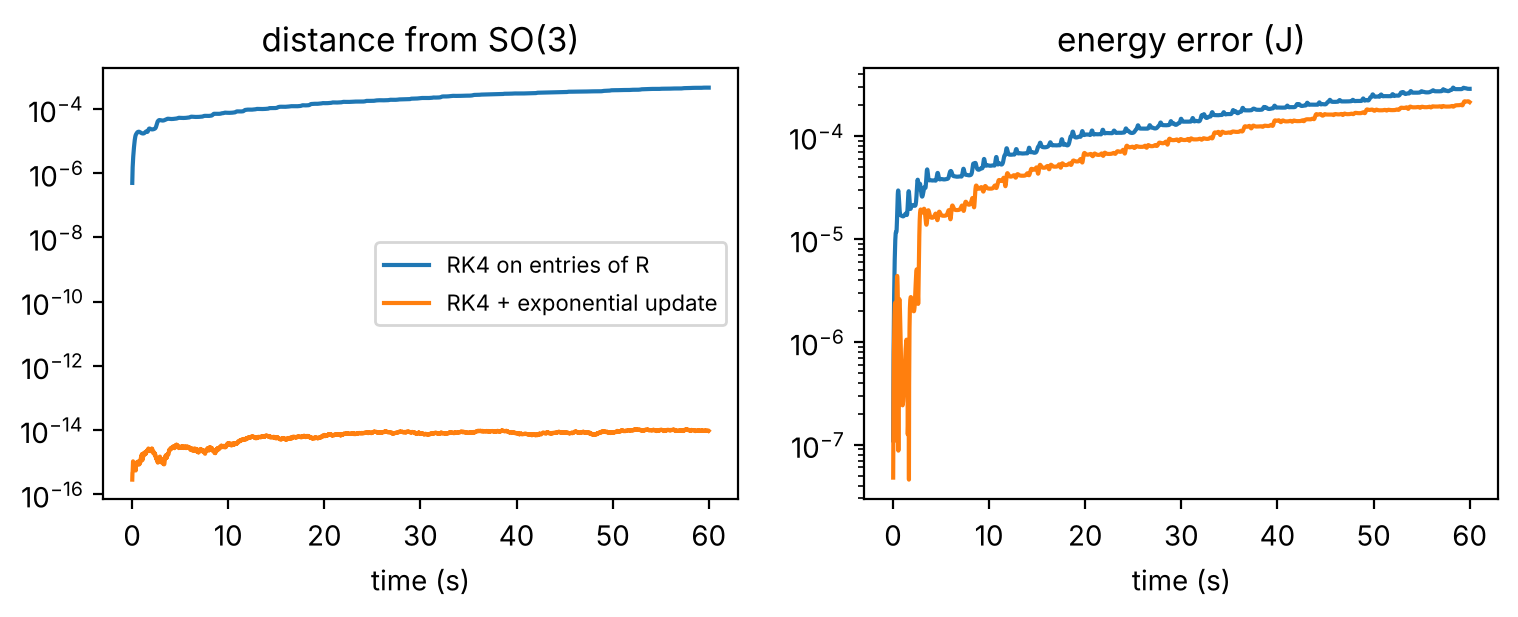

In [10]:
def pend_accel(R, Om):
    return np.linalg.solve(J_p, -np.cross(Om, J_p @ Om) + m_p * G * np.cross(R.T @ E3, rho_p))


def pend_energy(R, Om):
    return 0.5 * Om @ J_p @ Om + m_p * G * E3 @ (R @ rho_p)


def rk4(f, a, b, h):
    k1 = f(a, b); k2 = f(a + h / 2 * k1[0], b + h / 2 * k1[1])
    k3 = f(a + h / 2 * k2[0], b + h / 2 * k2[1]); k4 = f(a + h * k3[0], b + h * k3[1])
    return a + h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]), b + h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])


def dexpinv(th, Om):
    return Om + 0.5 * np.cross(th, Om) + np.cross(th, np.cross(th, Om)) / 12


def step_naive(R, Om, h):
    return rk4(lambda R_, Om_: (R_ @ hat(Om_), pend_accel(R_, Om_)), R, Om, h)


def step_lie(R, Om, h):
    th, Om = rk4(lambda th_, Om_: (dexpinv(th_, Om_), pend_accel(R @ expm_so3(th_), Om_)), np.zeros(3), Om, h)
    return R @ expm_so3(th), Om


h, T_end = 0.02, 60.0
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9, 2.8))
for step, name in ((step_naive, "RK4 on entries of R"), (step_lie, "RK4 + exponential update")):
    R, Om = expm_so3(np.array([2.0, 0, 0])), np.array([0.0, 0.5, 6.0])
    E0, rows = pend_energy(R, Om), []
    for _ in range(int(T_end / h)):
        R, Om = step(R, Om, h)
        rows.append((np.linalg.norm(R.T @ R - np.eye(3)), abs(pend_energy(R, Om) - E0)))
    rows = np.array(rows)
    tt = h * np.arange(1, len(rows) + 1)
    a0.semilogy(tt, np.maximum(rows[:, 0], 1e-17), label=name); a1.semilogy(tt, rows[:, 1], label=name)
    print(f"{name:26s}: |R'R - I| = {rows[-1, 0]:.1e},  energy error = {rows[-1, 1]:.1e} J")
a0.set_title("distance from SO(3)"); a1.set_title("energy error (J)"); a0.legend(fontsize=8)
for a in (a0, a1):
    a.set_xlabel("time (s)")
plt.show()

## Starting points for the exercises

- **4.1** Check $\delta\omega = \dot\xi - 2\,\omega\times\xi = \dot\xi + 2(\xi\cdot\dot q)\,q$ by finite differences, reusing cell 3.
- **4.4** Fit the early growth of $\Omega_1, \Omega_3$ in cell 5 and compare with
  $\lambda = \Omega_2\sqrt{(J_2-J_1)(J_3-J_2)/(J_1J_3)}$.
- **4.5** Add the energy of the quadrotor and load to cell 6 and confirm it is constant after the cut.
- **4.7** Replace the RK4 steps of cell 7 by the first-order steps and tumble the book.